Given evenly-spaced data snapshots $x_1,\ldots,x_n$, Dynamic Mode Decomposition (DMD) finds the optimal matrix $A$ solving $Ax_j\approx x_{j+1}$ for $1\leq j\leq n-1$ (in the least squares sense), which is a discrete approximation for $\dot x=Ax$.

Formally, given data matrices

$$X=\begin{bmatrix} x_1 & x_2 & \cdots & x_{n-1}\end{bmatrix}\quad\text{and}\quad X'=\begin{bmatrix} x_2 & x_3 & \cdots & x_n \end{bmatrix},$$

we find $A$ minimizing $\|AX-X'\|_2.$ There is an exact solution $A=X'X^{\dagger}.$

However, computing $X'X^{\dagger}$ and its eigenvalues/eigenvectors is too costly. So instead we use low rank approximations $X_r$ and $X_r'$ to $X$ and $X'$ respectively, and then find the eigenvalues and eigenvectors of a matrix similar to $X_r'X_r^{\dagger}$.

Our solution ultimately takes the form

$$x_i\approx\sum_{j=1}^r b_j\phi_j e^{\lambda_jt_i}.$$

We'll start by importing packages.

In [1]:
import numpy as np # Matrix and vector algebra
import matplotlib.pylab as plt # Plotting
import pandas as pd # Tables
from pydmd import BOPDMD, plotter,DMD # BOPDMD/DMD implementation and a helpful plotting function
from tqdm import tqdm # Progress bars
from sklearn.decomposition import PCA # PCA for comparisons
np.set_printoptions(suppress=True,precision=8,linewidth=100000) # Improve print statements
plt.rcParams['figure.dpi']=400 # Use higher resolution figures
plt.rcParams['text.usetex']=True # Use LaTeX in plots

Next we'll load the data.

In [16]:
# Wide field data temporal components
widefielddata = np.load("../Mouse Data/svdTemporalComponents_corr.npy")

# DMD assumes each time point is a column
widefielddata = widefielddata.T

# Normalize to avoid overflow from calculating exponentials of large numbers
SV_norm = np.linalg.norm(widefielddata,keepdims=True)
SV_normalized = widefielddata / SV_norm

Now we fit the first 3000 time points of the first 20 PCA components with 10 DMD modes. Note that there is no experiment, and hence no external stimulus, during this time period.

In [17]:
dmd_model = DMD(svd_rank=10).fit(SV_normalized[:20,:3000])

One of the main attractions of DMD is that, like PCA, it compresses high-dimensional data into a handful of modes. Unlike PCA, with DMD each mode has an associated frequency coming from the imaginary part of the eigenvalue associated with that mode. In the plots below, we project the data onto the DMD modes, and plot each projection. We also sort the plots by the magnitude of the mode's associated eigenvalues (in column-major order, so that the plot in row 5, column 1 is associated with an eigenvalue with largest modulus in row 1, column 2).

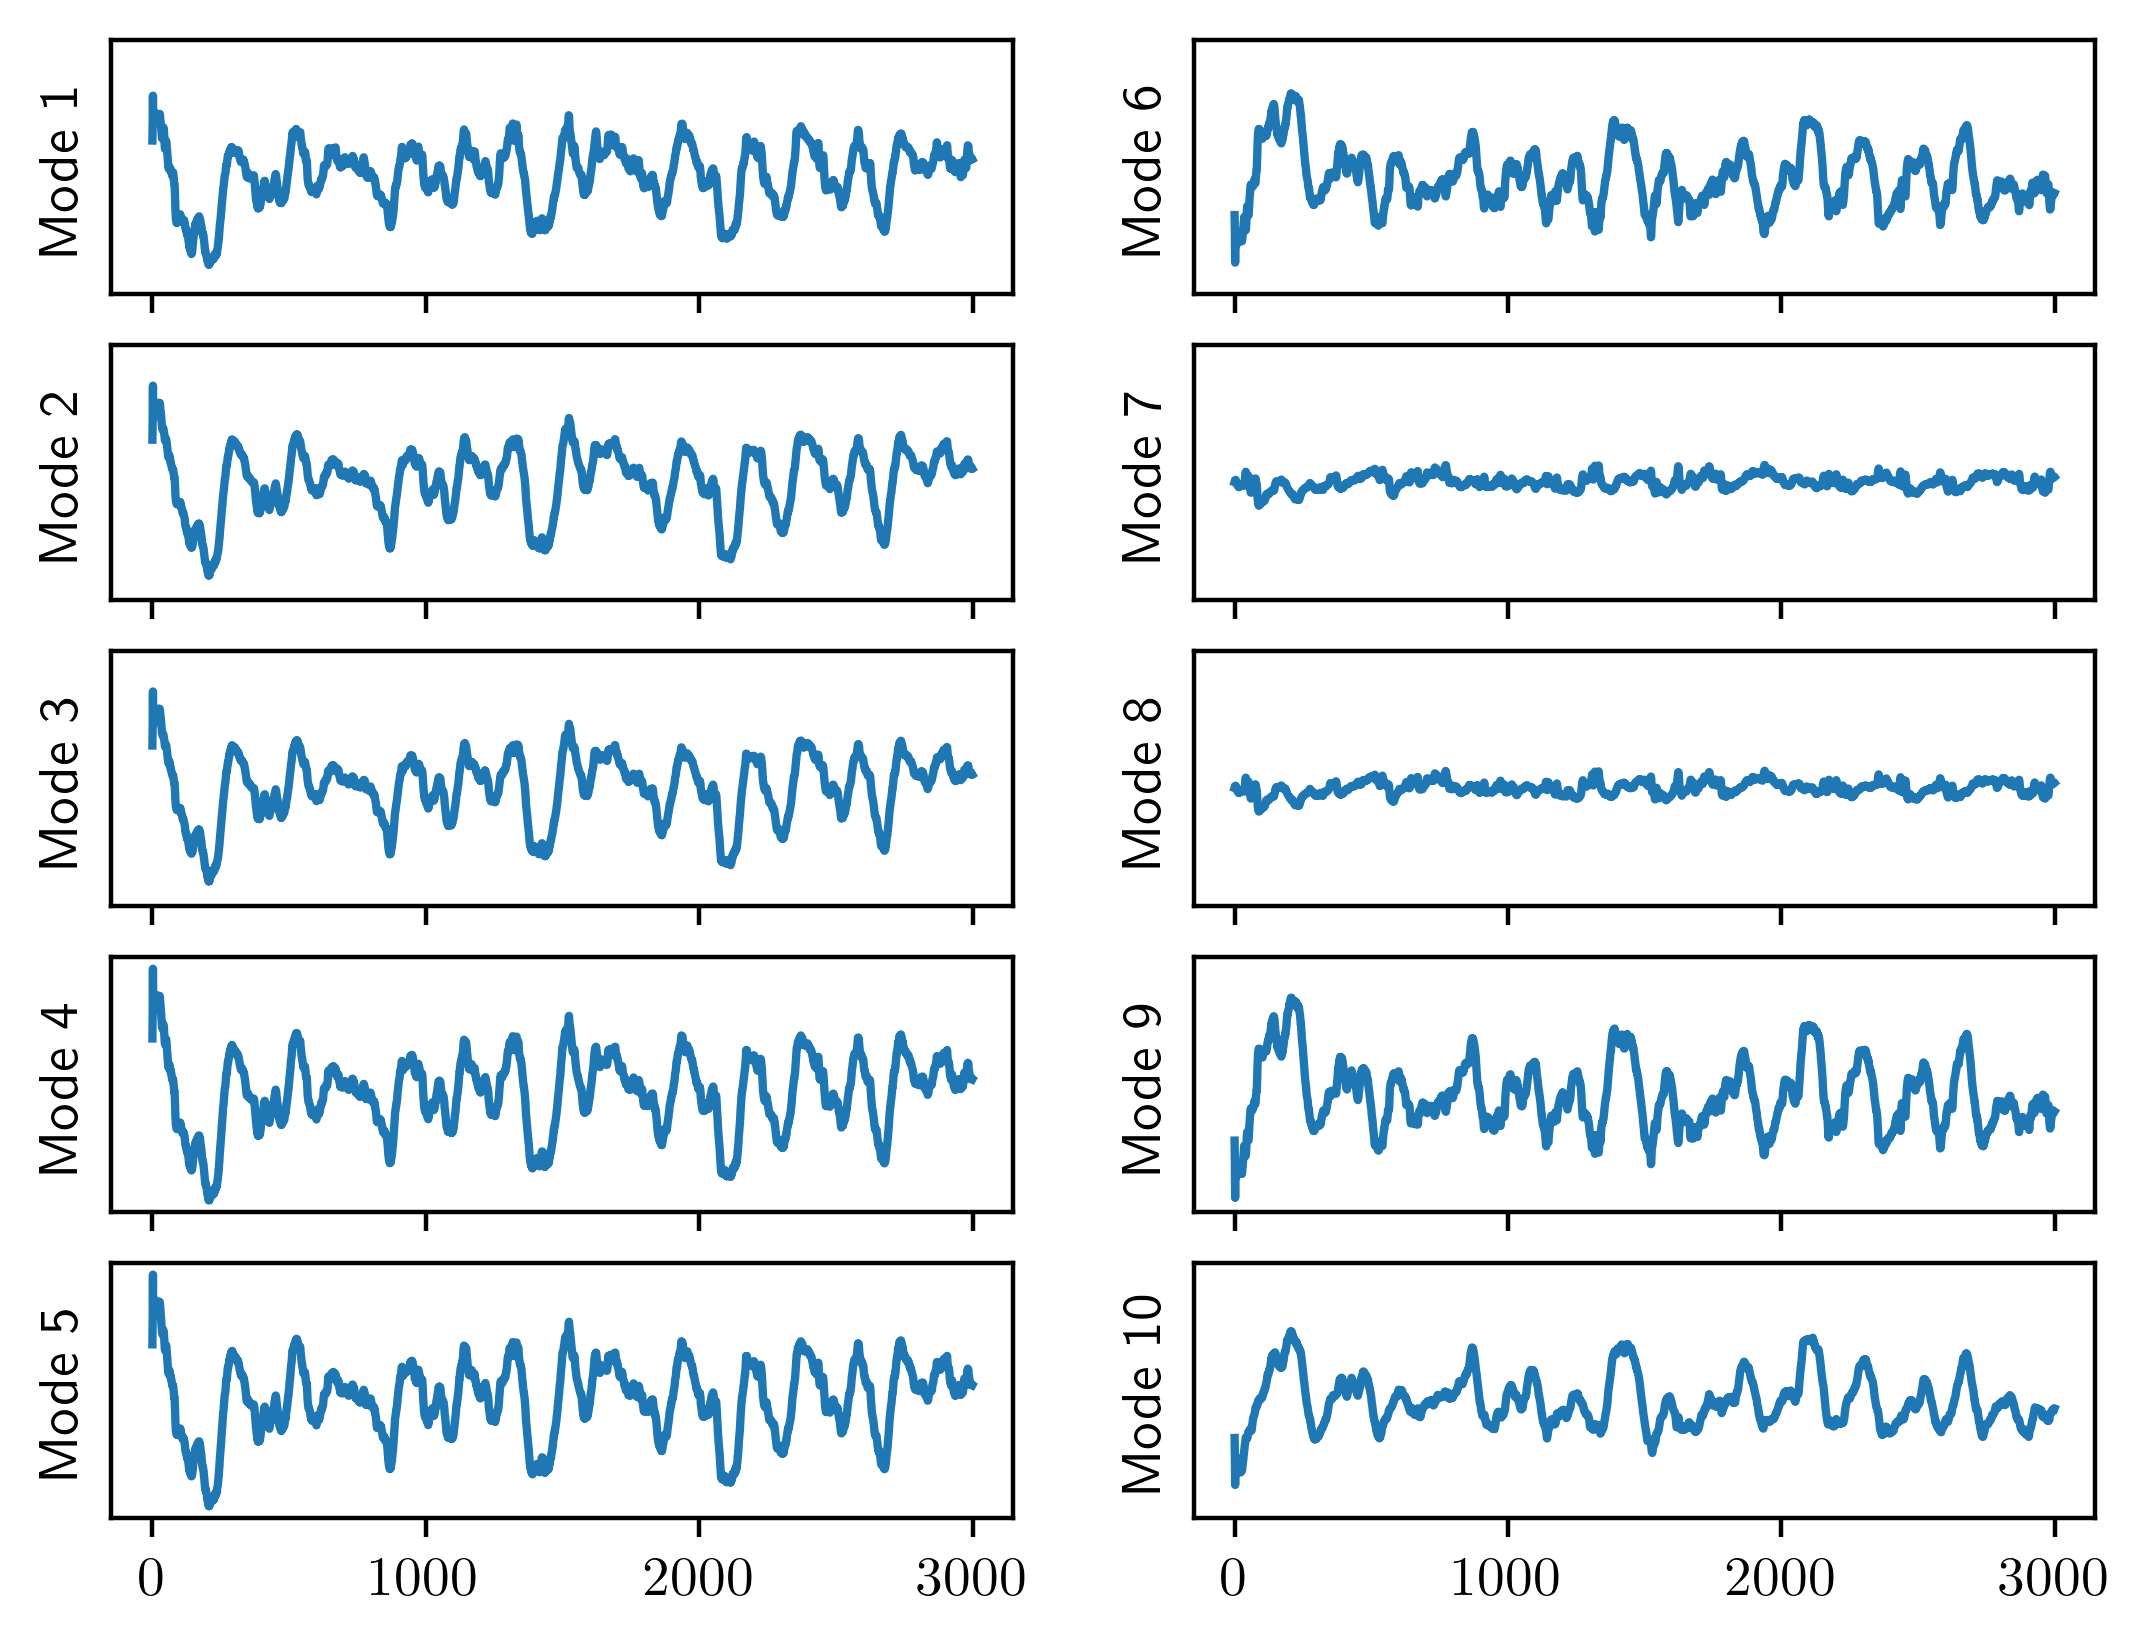

In [18]:
fig,ax = plt.subplots(5,2,sharex=True,sharey=True)
idx = np.argsort(np.abs(dmd_model.eigs))[::-1] # Get indices that sort eigenvalues in descending modulus order
proj = np.real(dmd_model.modes.T@SV_normalized[:20,:3000]) # Project modes onto data and take real part
proj = proj[idx,:] # Sort by the indices we found earlier
for j in range(2):
    for i in range(5):
        ax[i,j].plot(proj[5*j+i])
        ax[i,j].set_yticks([])
        ax[i,j].set_ylabel("Mode " + str(5*j+i+1))

These modes are not really interpretable because the widefield temporal components are not easily interpretable. We can do better by multiplying back the rest of the SVD of the widefield data. The result is a 3000 frame $560\times 560$ pixel video. I have not done this for DMD yet because, as we can see below, there is some reason to believe that the DMD fit is very poor. Before that though, let's look at the frequencies of each DMD mode. The formula for the frequency of the mode associated with eigenvalue $\lambda_j$ (assuming $\lambda_j$ is a discrete-time eigenvalue) is
$$\text{freq}_j=\frac{\left|\text{Imag }\log(\lambda_j)\right|}{2\pi\Delta t},$$
where $\Delta t$ is the time between each of our timepoints, which is $0.0285s$ in our case.  We will sort the frequencies in order of decreasing amplitude (the coefficients $b_j$ in the above formula).

In [19]:
df = pd.DataFrame()
dt = 0.0285
dmd_freqs = np.abs(np.imag(np.log(dmd_model.eigs))) / (2*np.pi*dt)
dmd_amplitudes = np.abs(dmd_model.amplitudes)
idx = np.argsort(dmd_amplitudes)[::-1]
df['Frequencies'] = dmd_freqs[idx]
df['Amplitudes'] = dmd_amplitudes[idx]
print(df)

   Frequencies  Amplitudes
0     0.140412    0.002519
1     0.140412    0.002519
2     0.000000    0.001489
3     0.000000    0.000632
4     0.093847    0.000531
5     0.093847    0.000531
6     0.000000    0.000530
7     0.000000    0.000350
8     0.048840    0.000077
9     0.048840    0.000077


We can see that a DMD fit with only ten modes finds only low frequency modes; the highest frequency mode completes only twelve periods during the entire 85.5s training window. Each of the modes comes in complex conjugate pairs because our data is real. It is surprising to me that we have two pairs of zero frequency modes (a single constant pair tends to be more common), and that our higher amplitude modes have higher frequencies. This may indicate that our DMD fit is not very good.

Let's plot the first ten components in the actual data and the reconstructed data.

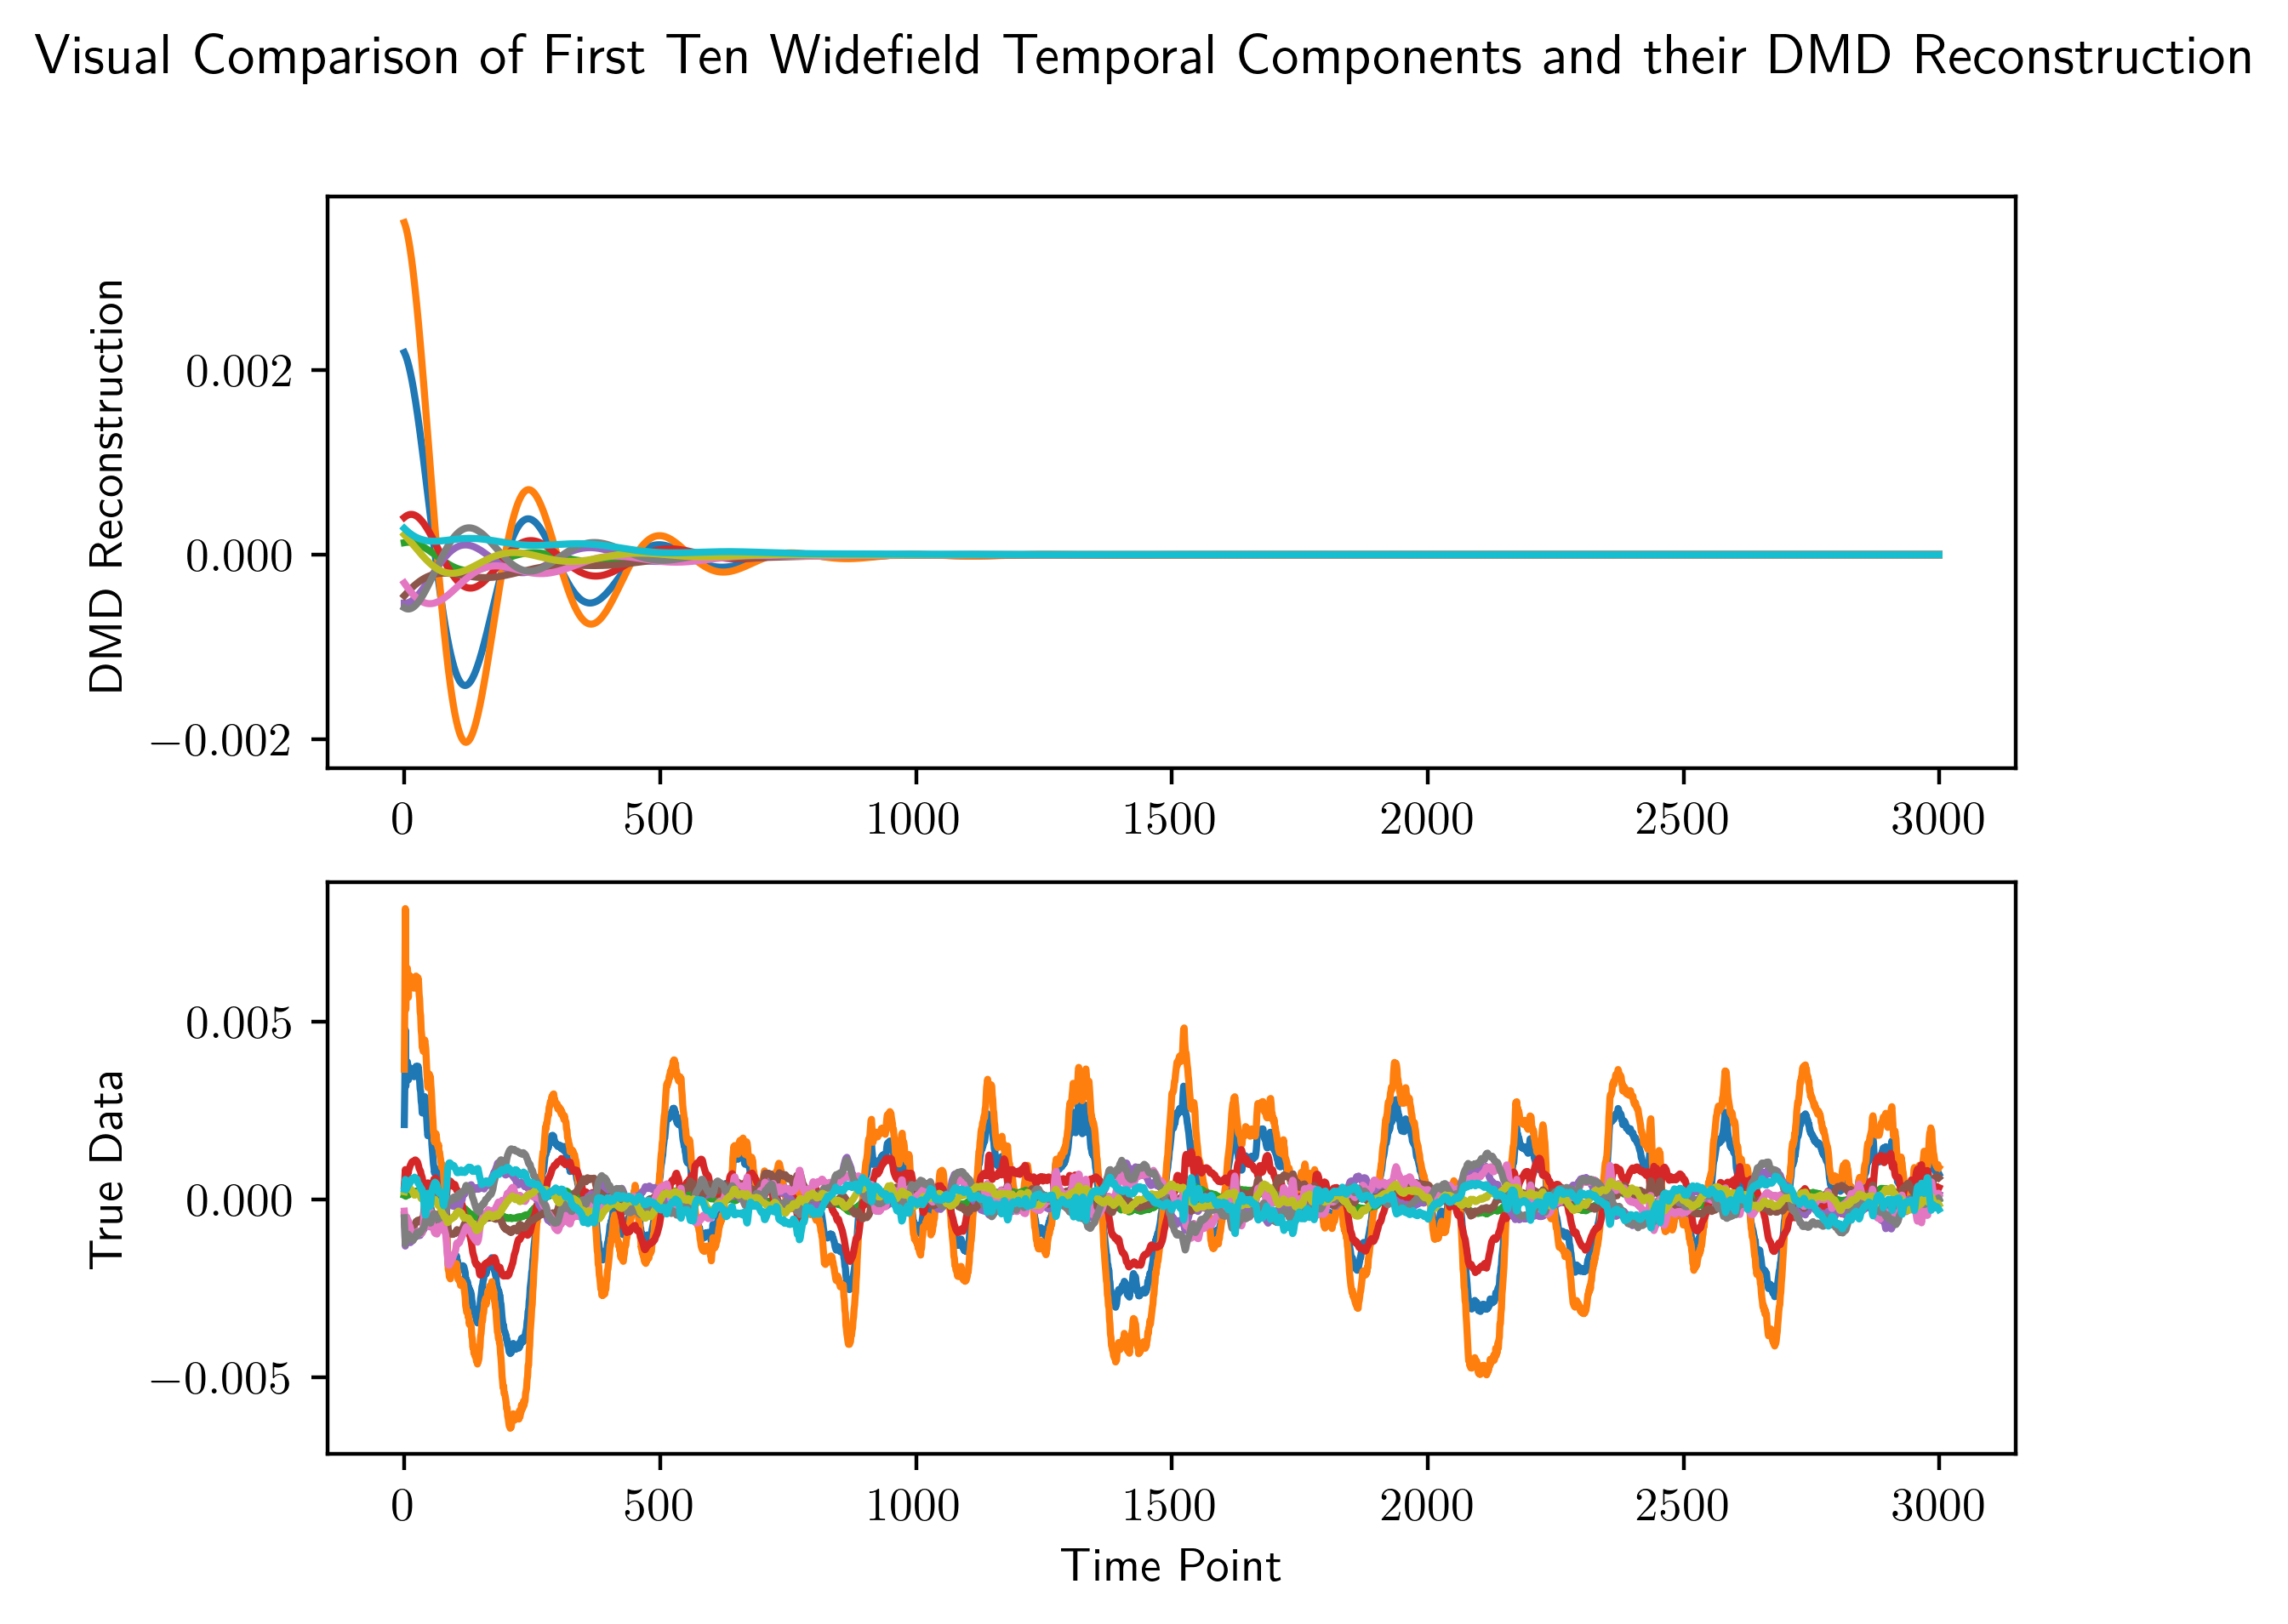

In [20]:
fig,ax = plt.subplots(2,1)
for i in range(10):
    ax[0].plot(np.real(dmd_model.reconstructed_data[i,:]))
    ax[0].set_ylabel("DMD Reconstruction")
    ax[1].plot(SV_normalized[i,:3000])
    ax[1].set_ylabel("True Data")
ax[1].set_xlabel("Time Point")
fig.suptitle("Visual Comparison of First Ten Widefield Temporal Components and their DMD Reconstruction");

As we can see, the DMD reconstruction decays to zero almost immediately. This is unfortunately typical of DMD. We can quantify the error with the relative squared error:
$$\text{RSE}(X,Y)=\frac{\sum_{i=1}^n(Y_i-X_i)^2}{\sum_{i=1}^n(Y_i-\bar Y_i)^2},$$
where $X$ is our reconstruction (flattened out into a length n vector), $Y$ is the flattened out true data, and $\bar Y$ is the mean of $Y$. The numerator in this error term reflects the average deviation between the reconstruction and the data, while the denominator is a normalization term that accounts for the fact that the data values themselves are small on average. An interpretation for this error is as a measure of how good our model is at predicting our data at each time point compared to us just predicting that at each time point the data is equal to its mean value. With this interpretation, RSEs larger than $1$ indicate a worse predictor than simply guessing that the data equals its mean, while RSEs between $0$ and $1$ indicate that our model is better, with the amount that we are better by being one over the RSE.

In [21]:
RSE = lambda X,Y: np.sum((Y-np.real(X))**2)/np.sum((Y-np.mean(Y))**2)
# Model reconstruction = X, true data = Y

In [22]:
print("RSE for the DMD fit: " + str(RSE(dmd_model.reconstructed_data,SV_normalized[:20,:3000])))

RSE for the DMD fit: 0.9109997914755351


So the DMD fit appears to be slightly better than just using the mean as our prediction. However, this is helped significantly by the fact that the mean is zero, so at later times using DMD and using the mean as our predictor are equivalent.

Fundamentally, the fit we achieve with DMD is optimal (in terms of one-step updates) in a least squares sense over the entire dataset that we fit, so that essentially we are assuming our data comes from a stationary process. This is an approximation that gets worse the longer the time series we use to fit is. Thus, we would expect a fit on a smaller amount of data to be better. Let's try 500 time points (14.25s) instead of 3000.

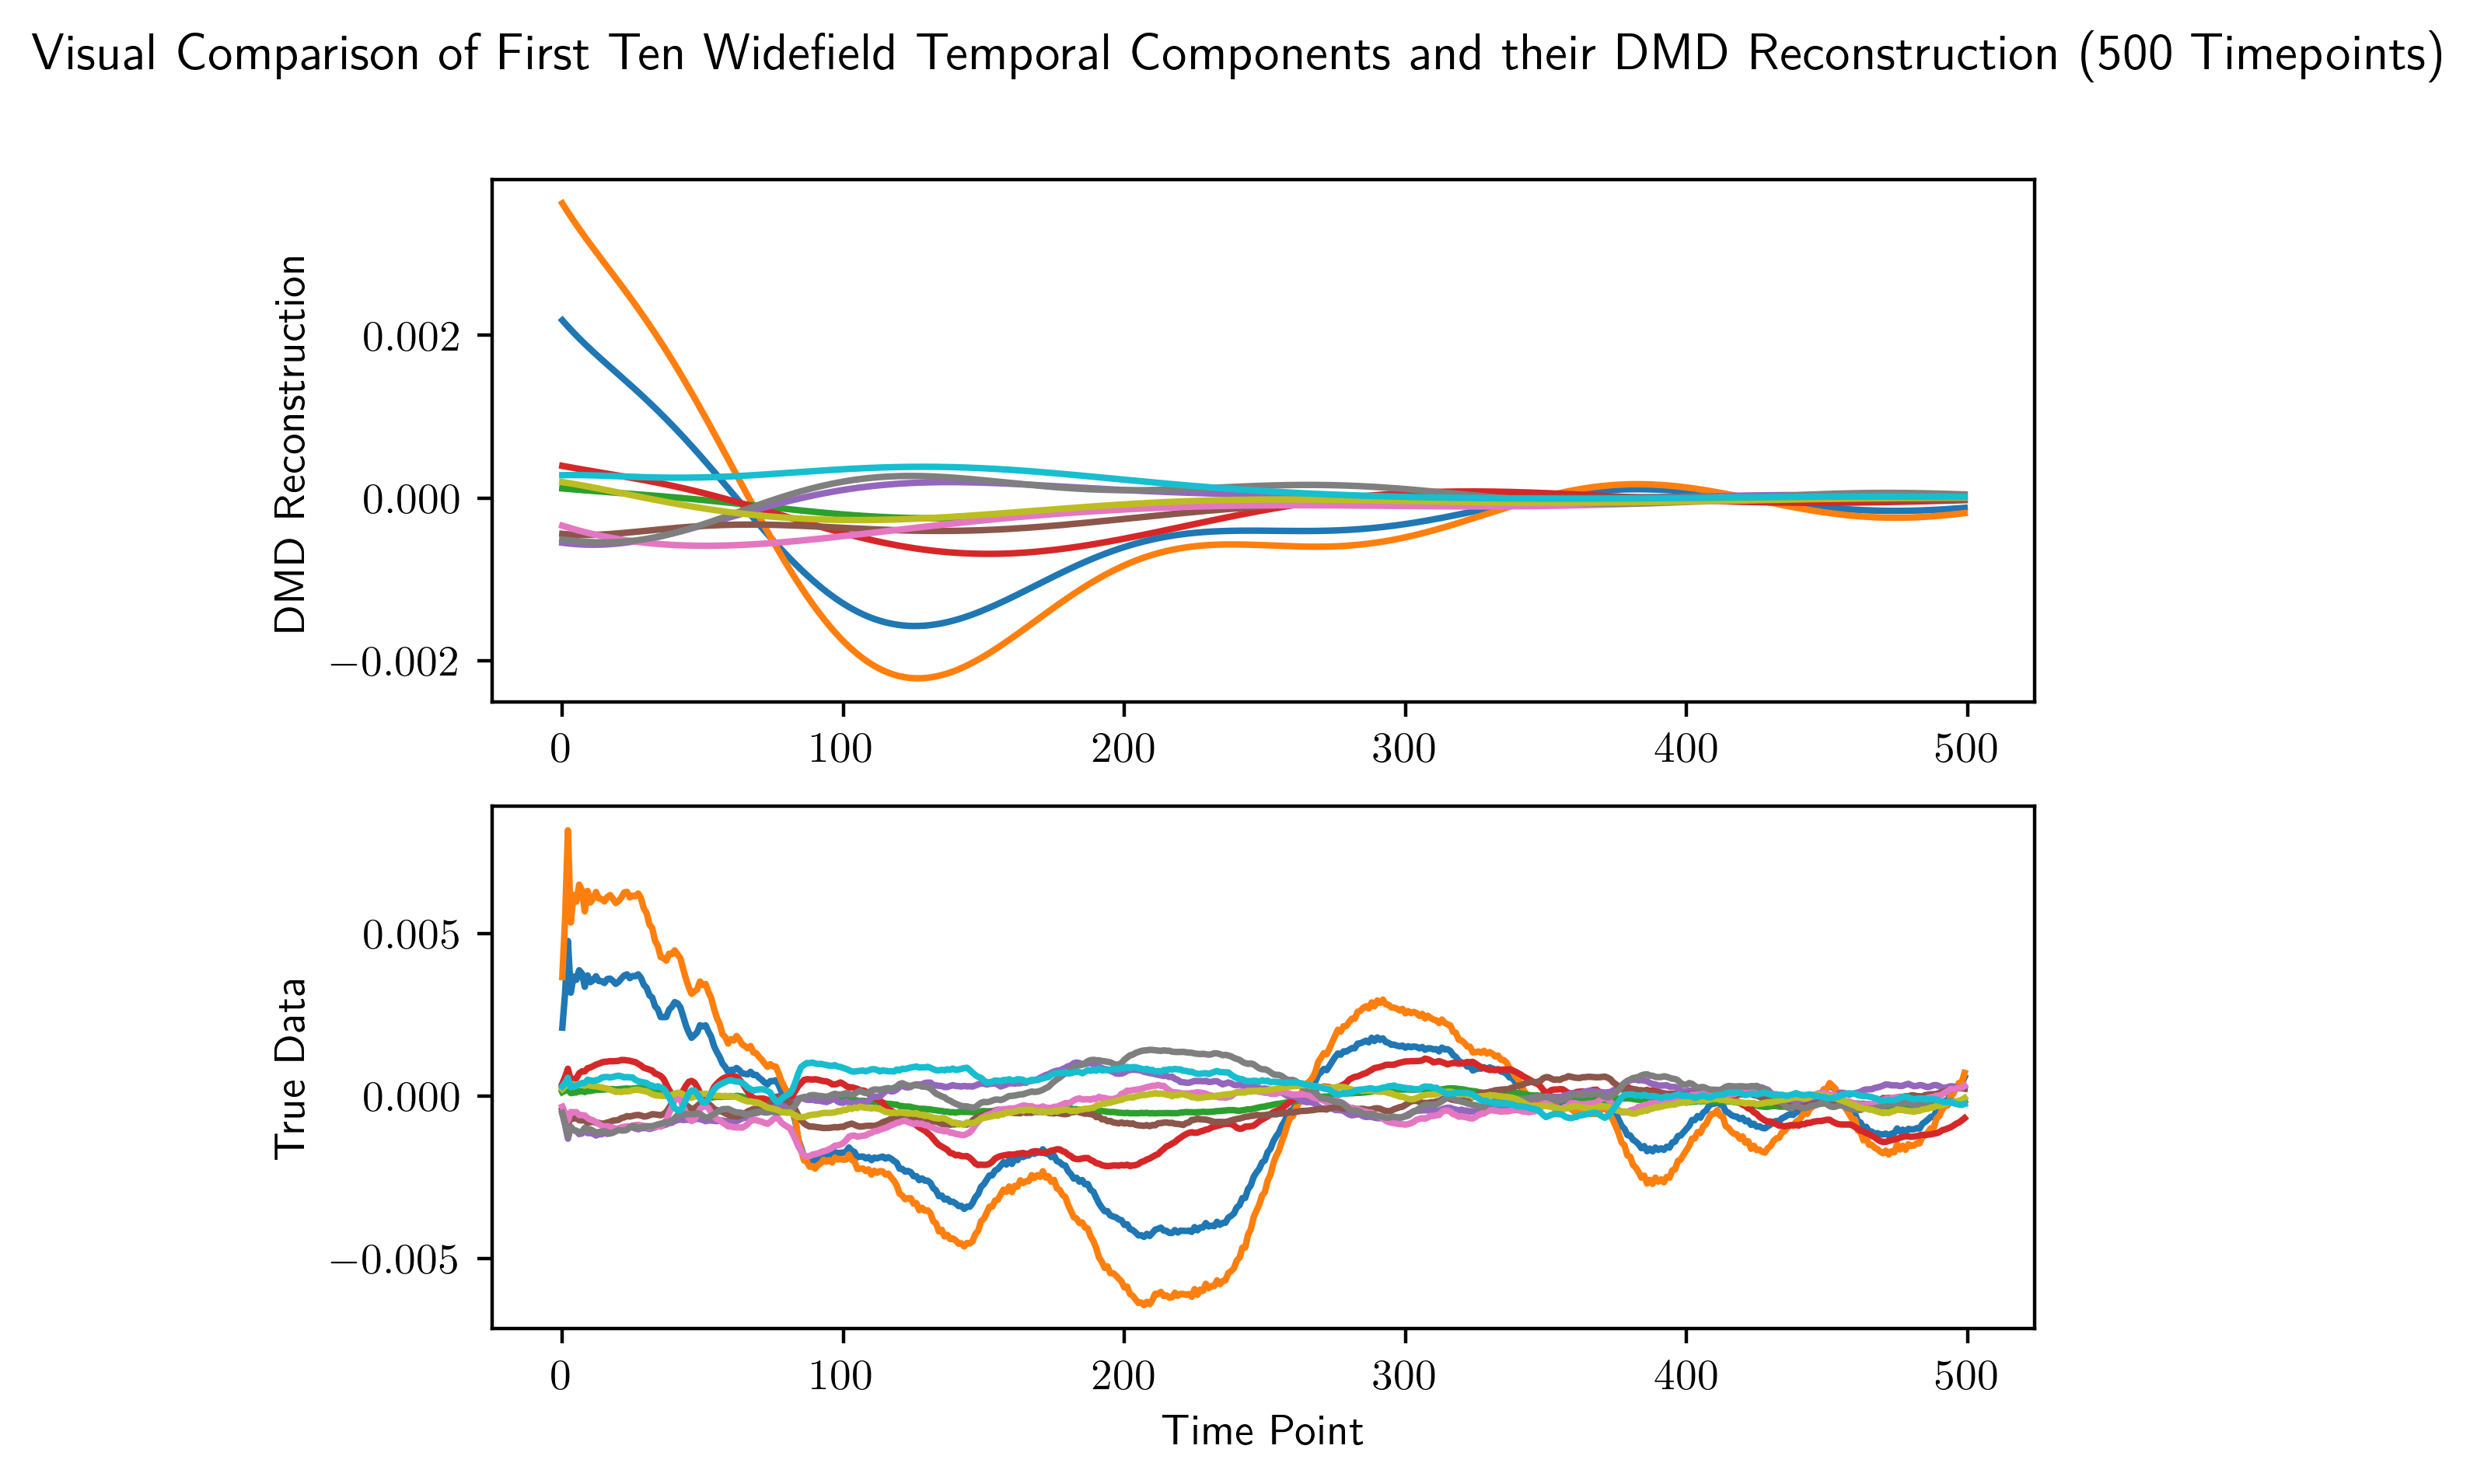

In [23]:
dmd_model_500_tp = DMD(svd_rank=10).fit(SV_normalized[:20,:500])
fig,ax = plt.subplots(2,1)
for i in range(10):
    ax[0].plot(np.real(dmd_model_500_tp.reconstructed_data[i,:]))
    ax[0].set_ylabel("DMD Reconstruction")
    ax[1].plot(SV_normalized[i,:500])
    ax[1].set_ylabel("True Data")
ax[1].set_xlabel("Time Point")
fig.suptitle("Visual Comparison of First Ten Widefield Temporal Components and their DMD Reconstruction (500 Timepoints)");

In [24]:
print("RSE for the DMD fit: " + str(RSE(dmd_model_500_tp.reconstructed_data,SV_normalized[:20,:500])))

RSE for the DMD fit: 0.5940288160866635


Let's look at the frequencies in this case.

In [25]:
df = pd.DataFrame()
dt = 0.0285
dmd_freqs = np.abs(np.imag(np.log(dmd_model_500_tp.eigs))) / (2*np.pi*dt)
dmd_amplitudes = np.abs(dmd_model_500_tp.amplitudes)
idx = np.argsort(dmd_amplitudes)[::-1]
df['Frequencies'] = dmd_freqs[idx]
df['Amplitudes'] = dmd_amplitudes[idx]
print(df)

   Frequencies  Amplitudes
0     0.043670    0.005377
1     0.043670    0.005377
2     0.000000    0.003276
3     0.127880    0.001164
4     0.127880    0.001164
5     0.000000    0.001043
6     0.189965    0.000925
7     0.189965    0.000925
8     0.228288    0.000468
9     0.228288    0.000468


The frequencies found in this case are higher than the frequencies found in the 3000 time point case. This is typical of fitting DMD to a smaller window of data.

Exact DMD does better when there is less data to fit, but the fit is still poor. Thankfully, we can do much better, e.g. OptDMD, MrOptDMD, and HankelDMD.